In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 스타일 설정
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# 한글 폰트 설정 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [13]:
# 데이터 경로
DATA_PATH = Path('../data/raw/health_fitness_dataset.csv')

# 데이터 로드
df = pd.read_csv(DATA_PATH)

print(f"데이터 크기: {df.shape}")
print(f"행 개수: {len(df):,}")
print(f"열 개수: {df.shape[1]}")

데이터 크기: (687701, 22)
행 개수: 687,701
열 개수: 22


In [14]:
# 처음 5개 행 확인
df.head()

# 데이터 타입 및 결측치 확인
df.info()

# 기술 통계
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 687701 entries, 0 to 687700
Data columns (total 22 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   participant_id            687701 non-null  int64  
 1   date                      687701 non-null  object 
 2   age                       687701 non-null  int64  
 3   gender                    687701 non-null  object 
 4   height_cm                 687701 non-null  float64
 5   weight_kg                 687701 non-null  float64
 6   activity_type             687701 non-null  object 
 7   duration_minutes          687701 non-null  int64  
 8   intensity                 687701 non-null  object 
 9   calories_burned           687701 non-null  float64
 10  avg_heart_rate            687701 non-null  int64  
 11  hours_sleep               687701 non-null  float64
 12  stress_level              687701 non-null  int64  
 13  daily_steps               687701 non-null  i

,participant_id,age,height_cm,weight_kg,duration_minutes,calories_burned,avg_heart_rate,hours_sleep,stress_level,daily_steps,hydration_level,bmi,resting_heart_rate,blood_pressure_systolic,blood_pressure_diastolic,fitness_level
count,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000,687701.000000
mean,1499.781828,41.658602,168.587699,94.921981,70.011671,15.381302,131.454165,7.048799,5.252389,8628.370918,2.499427,22.733134,70.010547,120.001260,80.188079,9.524900
std,865.997215,13.581770,9.140811,22.461801,29.147251,9.985552,17.814744,0.972068,2.770029,2054.756608,0.579050,3.568383,5.074563,10.008917,8.239418,5.502485
min,1.000000,18.000000,145.000000,45.300000,20.000000,0.800000,82.000000,4.000000,1.000000,-419.000000,1.500000,14.200000,51.100000,78.000000,53.700000,0.020000
25%,749.000000,30.000000,161.700000,78.200000,45.000000,7.800000,118.000000,6.400000,3.000000,7203.000000,2.000000,20.100000,66.500000,113.100000,74.600000,4.770000
50%,1499.000000,42.000000,168.200000,94.600000,70.000000,13.000000,130.000000,7.000000,5.000000,8607.000000,2.500000,22.400000,70.000000,120.200000,80.100000,9.510000
75%,2249.000000,53.000000,175.300000,110.500000,95.000000,20.700000,144.000000,7.700000,8.000000,10027.000000,3.000000,25.100000,73.500000,127.000000,85.700000,14.230000
max,3000.000000,64.000000,198.500000,188.400000,120.000000,92.000000,206.000000,10.000000,10.000000,17241.000000,3.500000,38.800000,87.100000,152.700000,112.100000,21.930000


In [15]:
# 결측치 개수
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    '결측치 개수': missing,
    '비율(%)': missing_pct
})

missing_df[missing_df['결측치 개수'] > 0]

,결측치 개수,비율(%)
health_condition,490275,71.291884


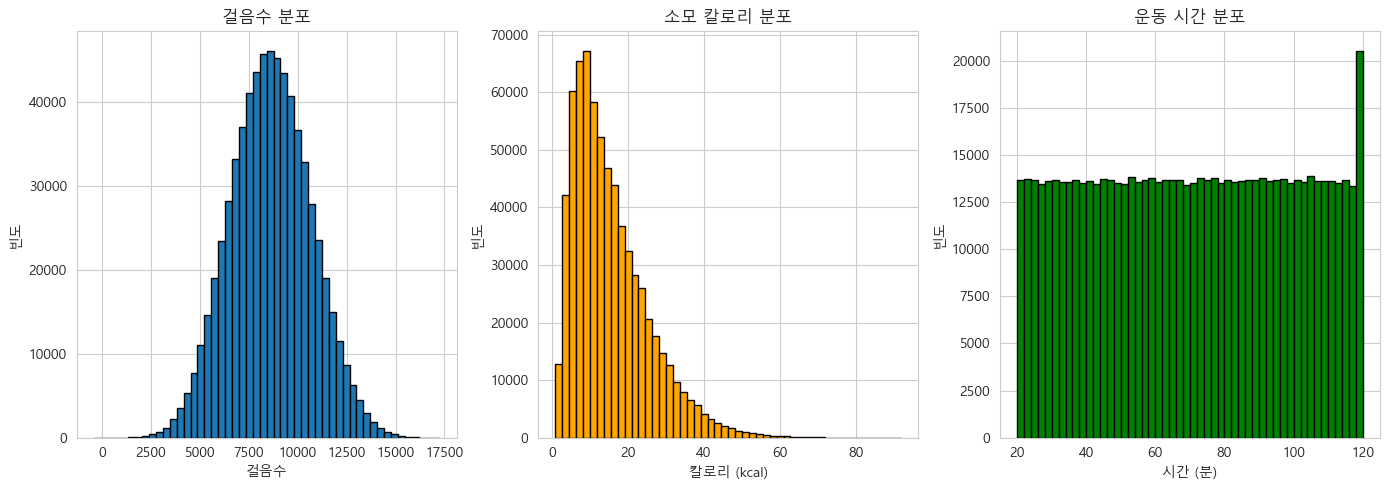

In [16]:
# 걸음수, 칼로리, 운동시간 분포
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.hist(df['daily_steps'], bins=50, edgecolor='black')
plt.title('걸음수 분포')
plt.xlabel('걸음수')
plt.ylabel('빈도')

plt.subplot(1, 3, 2)
plt.hist(df['calories_burned'], bins=50, edgecolor='black', color='orange')
plt.title('소모 칼로리 분포')
plt.xlabel('칼로리 (kcal)')
plt.ylabel('빈도')

plt.subplot(1, 3, 3)
plt.hist(df['duration_minutes'], bins=50, edgecolor='black', color='green')
plt.title('운동 시간 분포')
plt.xlabel('시간 (분)')
plt.ylabel('빈도')

plt.tight_layout()
plt.show()

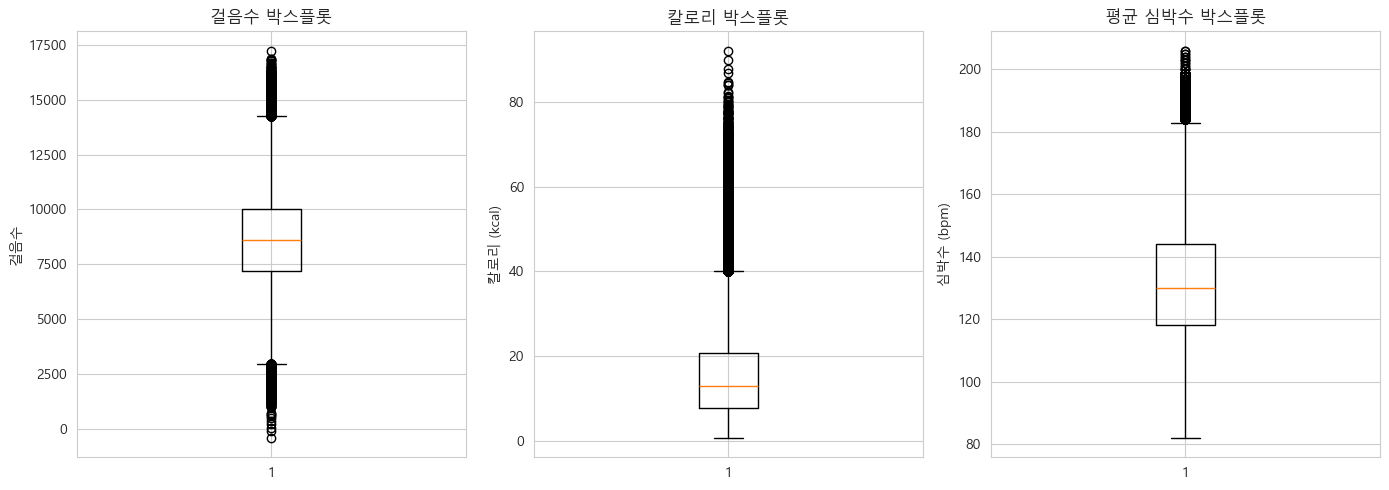

=== 이상치 확인 ===

걸음수 0인 경우: 0개
심박수 > 200: 13개
운동시간 > 180분: 0개


In [17]:
# 박스플롯으로 이상치 확인
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.boxplot(df['daily_steps'])
plt.title('걸음수 박스플롯')
plt.ylabel('걸음수')

plt.subplot(1, 3, 2)
plt.boxplot(df['calories_burned'])
plt.title('칼로리 박스플롯')
plt.ylabel('칼로리 (kcal)')

plt.subplot(1, 3, 3)
plt.boxplot(df['avg_heart_rate'])
plt.title('평균 심박수 박스플롯')
plt.ylabel('심박수 (bpm)')

plt.tight_layout()
plt.show()

# 극단적인 이상치 확인
print("=== 이상치 확인 ===")
print(f"\n걸음수 0인 경우: {len(df[df['daily_steps'] == 0])}개")
print(f"심박수 > 200: {len(df[df['avg_heart_rate'] > 200])}개")
print(f"운동시간 > 180분: {len(df[df['duration_minutes'] > 180])}개")

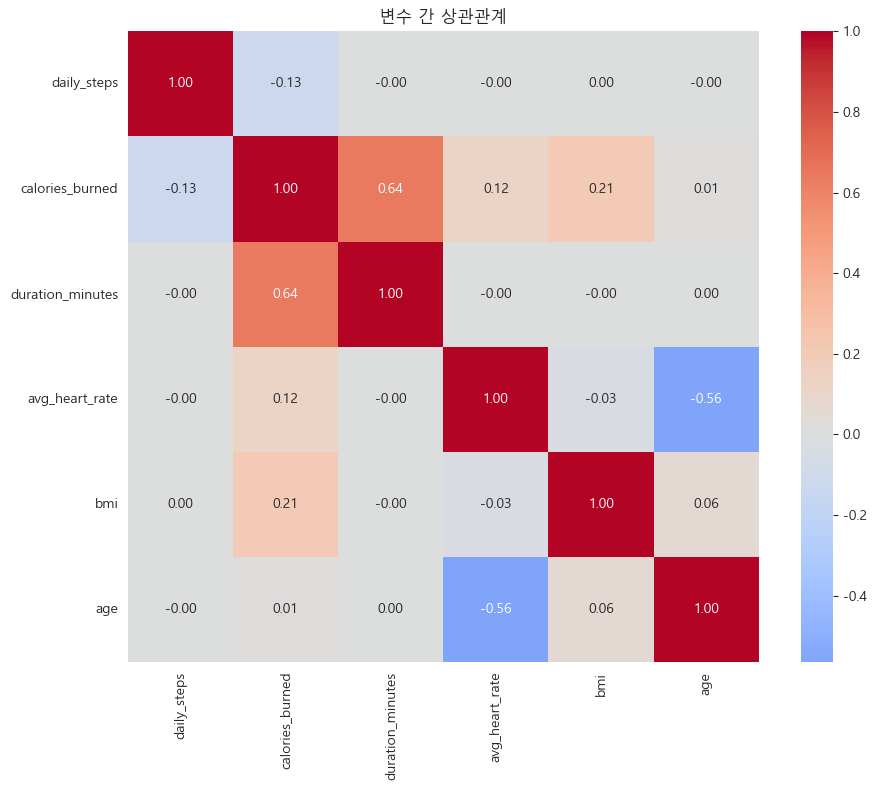

In [18]:
# 주요 변수들의 상관관계
correlation_vars = ['daily_steps', 'calories_burned', 'duration_minutes', 
                   'avg_heart_rate', 'bmi', 'age']

plt.figure(figsize=(10, 8))
sns.heatmap(df[correlation_vars].corr(), annot=True, fmt='.2f', 
            cmap='coolwarm', center=0, square=True)
plt.title('변수 간 상관관계')
plt.tight_layout()
plt.show()

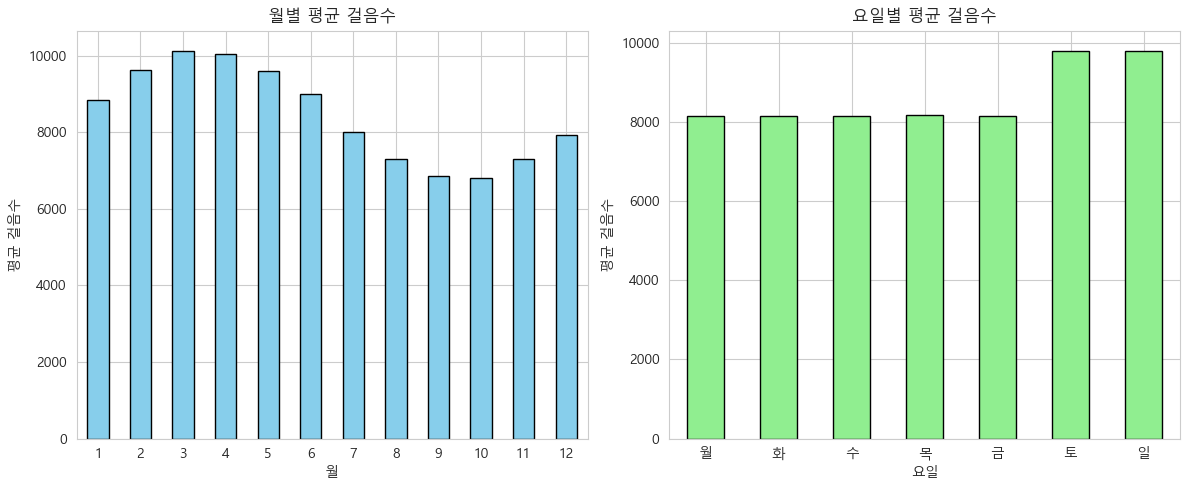

In [19]:
# 날짜 컬럼을 datetime으로 변환
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek  # 0=월요일, 6=일요일

# 월별 평균 걸음수
monthly_avg = df.groupby('month')['daily_steps'].mean()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
monthly_avg.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('월별 평균 걸음수')
plt.xlabel('월')
plt.ylabel('평균 걸음수')
plt.xticks(rotation=0)

# 요일별 평균 걸음수
weekday_avg = df.groupby('day_of_week')['daily_steps'].mean()
weekday_labels = ['월', '화', '수', '목', '금', '토', '일']

plt.subplot(1, 2, 2)
weekday_avg.plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('요일별 평균 걸음수')
plt.xlabel('요일')
plt.ylabel('평균 걸음수')
plt.xticks(range(7), weekday_labels, rotation=0)

plt.tight_layout()
plt.show()


=== 계절별 평균 ===
        daily_steps  calories_burned  duration_minutes
season                                                
가을      6994.742919        18.574473         70.076635
겨울      8894.523126        13.725801         70.012392
봄       9937.975671        13.749214         70.116553
여름      8145.185962        16.334849         69.826175


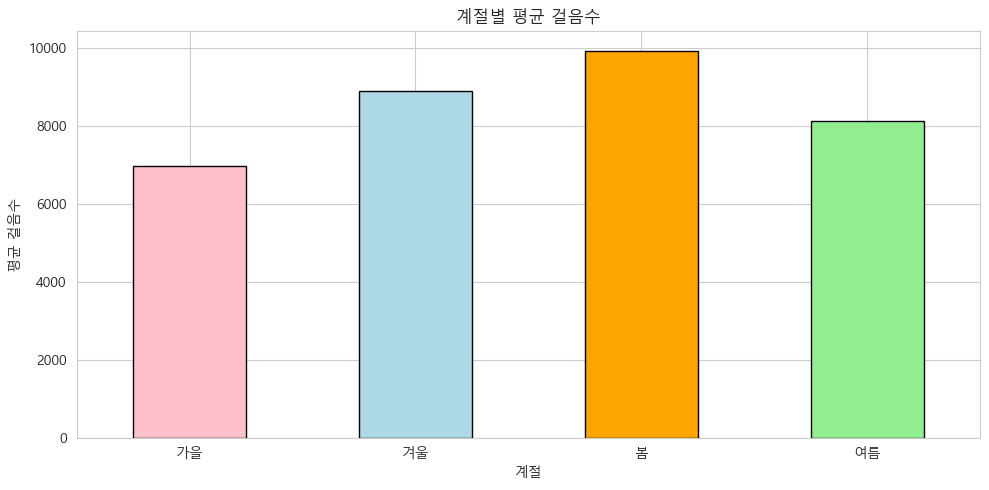

In [20]:
# 계절 분류 함수
def get_season(month):
    if month in [3, 4, 5]:
        return '봄'
    elif month in [6, 7, 8]:
        return '여름'
    elif month in [9, 10, 11]:
        return '가을'
    else:
        return '겨울'

df['season'] = df['month'].apply(get_season)

# 계절별 평균 비교
season_stats = df.groupby('season')[['daily_steps', 'calories_burned', 'duration_minutes']].mean()
print("\n=== 계절별 평균 ===")
print(season_stats)

# 시각화
season_stats['daily_steps'].plot(kind='bar', figsize=(10, 5), 
                                  color=['pink', 'lightblue', 'orange', 'lightgreen'],
                                  edgecolor='black')
plt.title('계절별 평균 걸음수')
plt.xlabel('계절')
plt.ylabel('평균 걸음수')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
# 다음 노트북을 위해 데이터프레임 저장
df.to_csv('../data/processed/data.csv', index=False)